# Audio — Deteksi Anomali Suara Mesin
**Kapan dipakai:** data train hanya berisi rekaman mesin NORMAL, lalu kita diminta menebak
rekaman mana yang rusak/aneh (soal gaya DCASE/MIMII).

**Idenya:** kita tidak tahu wujud suara rusak, jadi model hanya belajar seperti apa suara
normal. Rekaman yang "jauh" dari suara normal diberi anomaly score tinggi.

**Langkah:**
1. Ubah tiap rekaman menjadi satu baris angka (feature).
2. Model anomaly detection belajar dari suara normal, lalu memberi skor ke rekaman test.
3. Simpan skor sebagai submission.

**Data demo:** DCASE 2020 ToyCar (mobil mainan). Train: 100 rekaman normal.
Test: 50 normal + 50 rusak. Tiap rekaman 10 detik.

In [1]:
import glob
import os
import subprocess

import imageio_ffmpeg
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyod.models.copod import COPOD
from pyod.models.ecod import ECOD
from pyod.models.gmm import GMM
from pyod.models.hbos import HBOS
from pyod.models.iforest import IForest
from pyod.models.kde import KDE
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.models.ocsvm import OCSVM
from pyod.models.pca import PCA
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

## Konfigurasi
Semua yang boleh diubah ada di sel ini. Saat lomba, biasanya cukup ganti `DATA_FOLDER`.

In [2]:
DATA_FOLDER = "../../../data_latihan/audio/mesin_toycar"   # GANTI saat lomba
TRAIN_FOLDER = f"{DATA_FOLDER}/train"
TEST_FOLDER = f"{DATA_FOLDER}/test"

AUDIO_EXTENSION = "wav"     # wav, mp3, flac, ogg bisa langsung dibaca
VIDEO_EXTENSION = "mp4"     # mp4/m4a/webm/mkv: suaranya diambil dulu menjadi .wav (sel di bawah)
ANOMALY_PREFIX = "anomaly"  # nama file test yang diawali kata ini = rekaman rusak (label 1)

SAMPLE_RATE = 16000         # jumlah sampel per detik: semua rekaman dibaca dengan laju yang sama
HOP_LENGTH = 512            # jarak antar potongan pendek (frame), dalam jumlah sampel
SILENCE_THRESHOLD = 0.05    # frame dianggap diam kalau energinya < 5% dari frame terkeras
N_MELS = 64                 # jumlah pita frekuensi mel (makin banyak = makin rinci)
SEED = 42

## Ambil suara dari file video (hanya kalau ada)
`librosa` tidak bisa membaca mp4. Sel ini mencari file `VIDEO_EXTENSION` di folder train
dan test, lalu menyimpan suaranya sebagai `.wav` di sebelahnya (mono, `SAMPLE_RATE`).
Kalau tidak ada file video, sel ini tidak melakukan apa-apa.
Video tanpa suara akan dilaporkan "gagal" beserta pesan dari ffmpeg.

In [3]:
ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()

for folder in [TRAIN_FOLDER, TEST_FOLDER]:
    video_files = sorted(glob.glob(f"{folder}/*.{VIDEO_EXTENSION}"))
    for video_path in video_files:
        wav_path = os.path.splitext(video_path)[0] + ".wav"
        command = [ffmpeg_path, "-y", "-loglevel", "error", "-i", video_path,
                   "-vn", "-ac", "1", "-ar", str(SAMPLE_RATE), wav_path]
        result = subprocess.run(command, capture_output=True, text=True)
        if result.returncode != 0:
            print("gagal:", video_path, result.stderr)
    print(folder, ":", len(video_files), "file video diubah ke wav")

../../../data_latihan/audio/mesin_toycar/train : 0 file video diubah ke wav
../../../data_latihan/audio/mesin_toycar/test : 0 file video diubah ke wav


## Daftar file dan label
`glob` mengambil semua file yang cocok dengan pola. `*.wav` = nama apa saja, berakhiran `.wav`.
`sorted` membuat urutan file selalu sama setiap kali dijalankan.
Kalau jumlah file 0: cek `DATA_FOLDER` dan `AUDIO_EXTENSION` di Konfigurasi.

In [4]:
train_files = sorted(glob.glob(f"{TRAIN_FOLDER}/*.{AUDIO_EXTENSION}"))
test_files = sorted(glob.glob(f"{TEST_FOLDER}/*.{AUDIO_EXTENSION}"))

test_labels = []
for path in test_files:
    file_name = os.path.basename(path)
    if file_name.startswith(ANOMALY_PREFIX):
        test_labels.append(1)
    else:
        test_labels.append(0)
test_labels = np.array(test_labels)

print("file train (normal semua):", len(train_files))
print("file test:", len(test_files), "| yang rusak:", test_labels.sum())

file train (normal semua): 100
file test: 100 | yang rusak: 50


## Langkah 1a — buang bagian yang diam
Mesin kadang berhenti sebentar. Bagian diam itu tidak berguna, jadi dibuang.
Caranya: hitung energi (RMS) tiap frame, simpan hanya frame yang cukup keras.

In [5]:
def remove_silence(audio):
    energy = librosa.feature.rms(y=audio, hop_length=HOP_LENGTH)[0]
    threshold = SILENCE_THRESHOLD * energy.max()
    active_frames = []
    for frame_number in range(len(energy)):
        if energy[frame_number] >= threshold:
            start = frame_number * HOP_LENGTH
            end = start + HOP_LENGTH
            active_frames.append(audio[start:end])
    return np.concatenate(active_frames)


# coba pada satu rekaman
example_audio, _ = librosa.load(train_files[0], sr=SAMPLE_RATE)
example_clean = remove_silence(example_audio)
print("durasi asli       :", round(len(example_audio) / SAMPLE_RATE, 2), "detik")
print("setelah buang diam:", round(len(example_clean) / SAMPLE_RATE, 2), "detik")

durasi asli       : 11.0 detik
setelah buang diam: 11.0 detik


## Langkah 1b — satu rekaman menjadi satu baris feature
- **Spectral feature:** centroid (terang/gelap suara), bandwidth (lebar), rolloff,
  zero-crossing rate (kasar/halus), RMS (keras/pelan). Diringkas jadi mean dan std.
- **Mel feature:** energi rata-rata tiap pita frekuensi, semacam "sidik jari" suara mesin.

In [6]:
def extract_features(path):
    audio, _ = librosa.load(path, sr=SAMPLE_RATE)
    audio = remove_silence(audio)
    row = {}
    series = {}
    series["centroid"] = librosa.feature.spectral_centroid(y=audio, sr=SAMPLE_RATE)[0]
    series["bandwidth"] = librosa.feature.spectral_bandwidth(y=audio, sr=SAMPLE_RATE)[0]
    series["rolloff"] = librosa.feature.spectral_rolloff(y=audio, sr=SAMPLE_RATE)[0]
    series["zcr"] = librosa.feature.zero_crossing_rate(audio)[0]
    series["rms"] = librosa.feature.rms(y=audio)[0]
    for name in series:
        row[f"{name}_mean"] = series[name].mean()
        row[f"{name}_std"] = series[name].std()
    mel = librosa.feature.melspectrogram(y=audio, sr=SAMPLE_RATE, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel)
    for band in range(N_MELS):
        row[f"mel{band}_mean"] = mel_db[band].mean()
        row[f"mel{band}_std"] = mel_db[band].std()
    return row


# coba pada satu rekaman
example_features = extract_features(train_files[0])
print("jumlah feature per rekaman:", len(example_features))

jumlah feature per rekaman: 138


## Langkah 1c — hitung feature semua rekaman
Butuh sekitar 1 menit untuk 200 rekaman.

In [7]:
train_rows = []
for path in train_files:
    train_rows.append(extract_features(path))
train_table = pd.DataFrame(train_rows)

test_rows = []
for path in test_files:
    test_rows.append(extract_features(path))
test_table = pd.DataFrame(test_rows)

print("train_table:", train_table.shape)
print("test_table :", test_table.shape)
train_table.head()

train_table: (100, 138)
test_table : (100, 138)


,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,zcr_mean,zcr_std,rms_mean,rms_std,...,mel59_mean,mel59_std,mel60_mean,mel60_std,mel61_mean,mel61_std,mel62_mean,mel62_std,mel63_mean,mel63_std
0,1256.636188,128.671954,1601.918333,121.968631,2587.527253,398.560777,0.070982,0.009966,0.023662,0.003802,...,-37.346600,2.926379,-36.648365,2.781253,-35.667320,2.388006,-35.279125,2.483267,-41.319149,2.421939
1,1476.334674,202.833578,1755.161674,114.723524,3178.165879,546.333234,0.079211,0.024086,0.021502,0.006230,...,-36.490917,2.371810,-35.933311,2.231083,-34.408531,1.833051,-35.305569,2.311037,-42.642254,2.740073
2,1444.244096,170.138390,1719.728514,125.747587,3113.939862,456.354387,0.087006,0.021269,0.021506,0.003527,...,-35.254662,3.314744,-34.320263,3.514103,-33.404881,3.496174,-32.722698,3.733552,-39.165642,3.747903
3,1472.455959,328.173929,1746.751009,265.655660,3282.044876,1019.962701,0.087889,0.024507,0.011198,0.002238,...,-40.290787,5.757422,-39.999958,5.758637,-39.084400,5.680713,-39.166821,5.793598,-46.526760,5.669450
4,1527.004520,179.511242,1912.167332,134.340999,3426.258176,589.586313,0.086419,0.016767,0.020401,0.002144,...,-33.843182,2.405345,-31.344812,2.662074,-28.902798,2.666466,-28.152367,2.876302,-34.636475,3.189079


## Samakan skala feature
Feature punya satuan berbeda (Hz, dB, ...). StandardScaler membuat semuanya sebanding.
Scaler belajar dari data train saja, lalu dipakai juga untuk data test.

In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train_table)
X_test = scaler.transform(test_table)

## Langkah 2 — model
Pilih SATU model: hapus `#` di depan baris model yang ingin dipakai, beri `#` pada baris lain.
Semua model dari pustaka `pyod` dipakai dengan cara yang sama:
`model.fit(X_train)` belajar dari suara normal, lalu `model.decision_function(X)` memberi
anomaly score (makin besar = makin aneh).
Metrik: ROC-AUC (1.0 = sempurna, 0.5 = sama dengan menebak acak). Label test hanya ada di data
demo; saat lomba biasanya tidak ada, jadi sel AUC dilewati.

In [9]:
model = KNN(n_neighbors=5, method="mean")            # jarak rata-rata ke 5 rekaman normal terdekat
# model = KNN(n_neighbors=5, method="largest")       # jarak ke tetangga ke-5
# model = LOF(n_neighbors=10)                        # kepadatan lokal dibanding tetangga
# model = IForest(n_estimators=300, random_state=SEED)   # Isolation Forest, cepat untuk data besar
# model = OCSVM()                                    # One-Class SVM
# model = PCA()                                      # error rekonstruksi PCA
# model = ECOD()                                     # tanpa parameter, sangat cepat
# model = COPOD()                                    # tanpa parameter, sangat cepat
# model = HBOS()                                     # histogram per feature
# model = GMM(n_components=2, random_state=SEED)     # campuran distribusi normal
# model = KDE()                                      # perkiraan kepadatan

model.fit(X_train)
test_scores = model.decision_function(X_test)
print("AUC test:", round(roc_auc_score(test_labels, test_scores), 3))

AUC test: 0.716


## Gambar: sebaran skor dan kurva ROC
Kiri: makin terpisah warna oranye (rusak) dari biru (normal), makin bagus.
Kanan: makin melengkung ke kiri-atas, makin bagus. Garis putus-putus = tebakan acak.

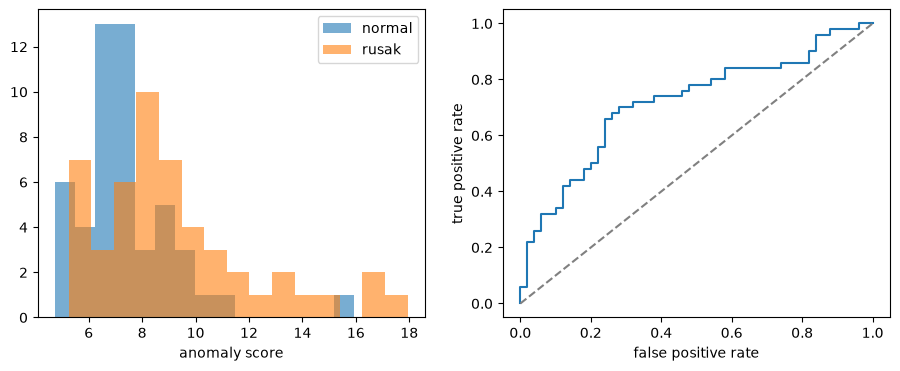

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(test_scores[test_labels == 0], bins=15, alpha=0.6, label="normal")
axes[0].hist(test_scores[test_labels == 1], bins=15, alpha=0.6, label="rusak")
axes[0].set_xlabel("anomaly score")
axes[0].legend()

fpr, tpr, _ = roc_curve(test_labels, test_scores)
axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
plt.show()

## Langkah 3 — submission
Satu skor per rekaman test. Nama kolom disalin dari format soal.
File `submission.csv` disimpan di folder yang sama dengan notebook ini.

In [11]:
predictions = model.decision_function(X_test)

file_names = []
for path in test_files:
    file_names.append(os.path.basename(path))

submission = pd.DataFrame()
submission["file"] = file_names
submission["anomaly_score"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,file,anomaly_score
0,anomaly_id_01_00000000.wav,7.950907
1,anomaly_id_01_00000001.wav,9.807028
2,anomaly_id_01_00000002.wav,15.041085
3,anomaly_id_01_00000003.wav,7.604699
4,anomaly_id_01_00000004.wav,16.423355
